In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

2.14.1+cu130 True NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression


tab = pd.read_csv("../data/processed/tabular.csv")
X_sp = np.load("../data/processed/spatial.npz")["X"]  #(N,6,40,60)
assert (tab["row_idx"].values == np.arange(len(tab))).all() and len(X_sp) == len(tab)

non_features = ["row_idx", "shot_id", "match_id", "team", "player", "period", "minute", "split", "goal"]
feat_cols = [c for c in tab.columns if c not in non_features]
idx = {s: tab.index[tab["split"] == s].to_numpy() for s in ["train", "val", "test"]}

scaler = StandardScaler().fit(tab.loc[idx["train"], feat_cols])   # train rows only
X_tab = scaler.transform(tab[feat_cols]).astype("float32")
y = tab["goal"].to_numpy().astype("float32")

In [4]:
def evaluate(y_true, p):
    return {"log_loss": log_loss(y_true, p), "auc": roc_auc_score(y_true, p), "brier": brier_score_loss(y_true, p)}

In [5]:
#baseline 1: always predicting the training goal rate
p_const = np.full(len(idx["val"]), y[idx["train"]].mean())
print("constant :", {k: round(v, 3) for k, v in evaluate(y[idx["val"]], p_const).items()})

constant : {'log_loss': 0.325, 'auc': 0.5, 'brier': 0.09}


In [6]:
# baseline 2: logistic regression
lr = LogisticRegression(max_iter=2000).fit(X_tab[idx["train"]], y[idx["train"]])
for s in ["val", "test"]:
    print("logistic", s, {k: round(v, 3) for k, v in evaluate(y[idx[s]], lr.predict_proba(X_tab[idx[s]])[:, 1]).items()})

logistic val {'log_loss': 0.276, 'auc': 0.78, 'brier': 0.079}
logistic test {'log_loss': 0.28, 'auc': 0.78, 'brier': 0.081}


#ANN

In [7]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42); np.random.seed(42)

def make_loader(split, shuffle):
    ix = idx[split]
    ds = TensorDataset(torch.from_numpy(X_tab[ix]), torch.from_numpy(y[ix]))
    return DataLoader(ds, batch_size=256, shuffle=shuffle)

class ANN(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers += [nn.Linear(d, 1)]          # raw logit out, no sigmoid
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

In [8]:
import copy
import matplotlib.pyplot as plt

def predict(model, loader):
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(torch.sigmoid(model(xb)))   # logit -> probability happens here
    return torch.cat(out).numpy()

def train_model(model, train_dl, val_dl, lr=1e-3, weight_decay=0.0, max_epochs=200, patience=15):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    y_val = np.concatenate([yb.numpy() for _, yb in val_dl])
    best = {"ll": np.inf, "state": None, "epoch": 0}
    hist = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in train_dl:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        tr_loss = total / len(train_dl.dataset)
        val_ll = log_loss(y_val, predict(model, val_dl))
        hist.append((tr_loss, val_ll))
        if val_ll < best["ll"] - 1e-4:                       # improved
            best = {"ll": val_ll, "state": copy.deepcopy(model.state_dict()), "epoch": epoch}
        elif epoch - best["epoch"] >= patience:              # no improvement for `patience` epochs
            break
    model.load_state_dict(best["state"])                     # go back to the best epoch
    return model, hist, best["epoch"]

best epoch: 12
ANN val: {'log_loss': 0.276, 'auc': 0.779, 'brier': 0.079}


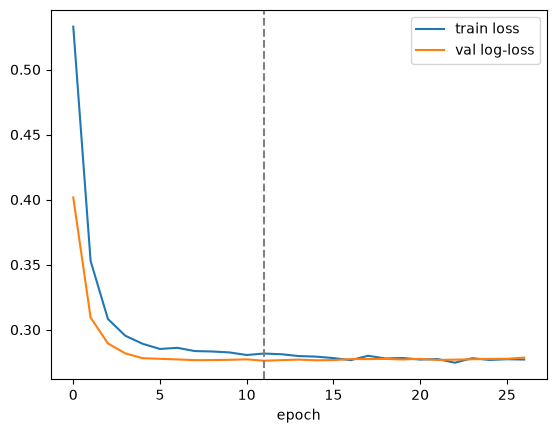

In [9]:
torch.manual_seed(42)
train_dl, val_dl, test_dl = make_loader("train", True), make_loader("val", False), make_loader("test", False)
model = ANN(len(feat_cols))
model, hist, best_ep = train_model(model, train_dl, val_dl)

print("best epoch:", best_ep)
print("ANN val:", {k: round(v, 3) for k, v in evaluate(y[idx["val"]], predict(model, val_dl)).items()})

h = np.array(hist)
plt.plot(h[:, 0], label="train loss"); plt.plot(h[:, 1], label="val log-loss")
plt.axvline(best_ep - 1, ls="--", c="gray"); plt.legend(); plt.xlabel("epoch"); plt.show()

In [10]:
import itertools
grid = {"hidden": [(32,), (64, 32), (128, 64)], "dropout": [0.1, 0.3], "lr": [1e-3, 3e-4]}

rows = []
for hidden, dropout, lr in itertools.product(grid["hidden"], grid["dropout"], grid["lr"]):
    lls, aucs, eps = [], [], []
    for seed in (0, 1, 2):
        torch.manual_seed(seed)
        m, _, ep = train_model(ANN(len(feat_cols), hidden, dropout), train_dl, val_dl, lr=lr)
        met = evaluate(y[idx["val"]], predict(m, val_dl))
        lls.append(met["log_loss"]); aucs.append(met["auc"]); eps.append(ep)
    rows.append(dict(hidden=hidden, dropout=dropout, lr=lr,
                     ll=np.mean(lls), ll_sd=np.std(lls), auc=np.mean(aucs), epoch=np.mean(eps)))

res = pd.DataFrame(rows).sort_values("ll")
print(res.round(4).to_string(index=False))

   hidden  dropout     lr     ll  ll_sd    auc   epoch
(128, 64)      0.3 0.0010 0.2767 0.0005 0.7776 11.6667
(128, 64)      0.3 0.0003 0.2768 0.0007 0.7783 21.6667
(128, 64)      0.1 0.0003 0.2768 0.0006 0.7775 17.6667
    (32,)      0.3 0.0010 0.2768 0.0005 0.7761 29.3333
(128, 64)      0.1 0.0010 0.2769 0.0008 0.7771  7.6667
    (32,)      0.3 0.0003 0.2769 0.0005 0.7766 86.6667
    (32,)      0.1 0.0010 0.2773 0.0009 0.7747 23.6667
 (64, 32)      0.3 0.0010 0.2773 0.0004 0.7766 14.6667
    (32,)      0.1 0.0003 0.2773 0.0011 0.7745 84.0000
 (64, 32)      0.3 0.0003 0.2774 0.0004 0.7760 49.6667
 (64, 32)      0.1 0.0010 0.2776 0.0004 0.7759 11.3333
 (64, 32)      0.1 0.0003 0.2780 0.0003 0.7742 37.0000


In [11]:
import os; os.makedirs("../results", exist_ok=True)
cfg = dict(hidden=(32,), dropout=0.3, lr=1e-3)

pv, pt = [], []
for seed in range(5):
    torch.manual_seed(seed)
    m, _, _ = train_model(ANN(len(feat_cols), cfg["hidden"], cfg["dropout"]), train_dl, val_dl, lr=cfg["lr"])
    pv.append(predict(m, val_dl)); pt.append(predict(m, test_dl))
np.save("../results/ann_val.npy", np.array(pv)); np.save("../results/ann_test.npy", np.array(pt))

ms = [evaluate(y[idx["val"]], p) for p in pv]
print({k: f"{np.mean([m[k] for m in ms]):.4f} ± {np.std([m[k] for m in ms]):.4f}" for k in ms[0]})

{'log_loss': '0.2771 ± 0.0005', 'auc': '0.7750 ± 0.0018', 'brier': '0.0792 ± 0.0001'}


### ANN final configuration

Grid: hidden ∈ {(32,), (64,32), (128,64)}, dropout ∈ {0.1, 0.3}, lr ∈ {1e-3, 3e-4}; 3 seeds each, selected on **validation log-loss** (test not used).

Result: all 12 configs fall within 0.2767–0.2780 (seed sd 0.0003–0.0011), so differences are within noise.

Rule: among configs within noise of the best, choose the simplest.
→ hidden=(32,), dropout=0.3, lr=1e-3 (val log-loss 0.2768).

Final ANN: this config trained on 5 seeds (0–4); val/test predictions saved to results/ann_val.npy, results/ann_test.npy.

# Cnn
- Input --> (6, 40, 60)

In [25]:
class SpatialDS(torch.utils.data.Dataset):
    def __init__(self, ix):
        self.X, self.y = X_sp[ix], torch.from_numpy(y[ix])    # stays float16 in memory
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return torch.from_numpy(self.X[i].astype(np.float32)), self.y[i]

def make_sp_loader(split, shuffle):
    return DataLoader(SpatialDS(idx[split]), batch_size=128, shuffle=shuffle)

class CNN(nn.Module):
    def __init__(self, ch=(16, 32, 64), k=3, dropout=0.3):
        super().__init__()
        layers, c_in = [], 6
        for c in ch:
            layers += [nn.Conv2d(c_in, c, k, padding=k // 2), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        n = self.features(torch.zeros(1, 6, 40, 60)).numel()      # flattened size
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(n, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)
torch.manual_seed(42)
sp_train, sp_val, sp_test = make_sp_loader("train", True), make_sp_loader("val", False), make_sp_loader("test", False)
cnn, hist, best_ep = train_model(CNN(), sp_train, sp_val, lr=1e-3, patience=10)
print("best epoch:", best_ep, {k: round(v, 3) for k, v in evaluate(y[idx["val"]], predict(cnn, sp_val)).items()})

best epoch: 8 {'log_loss': 0.301, 'auc': 0.719, 'brier': 0.084}


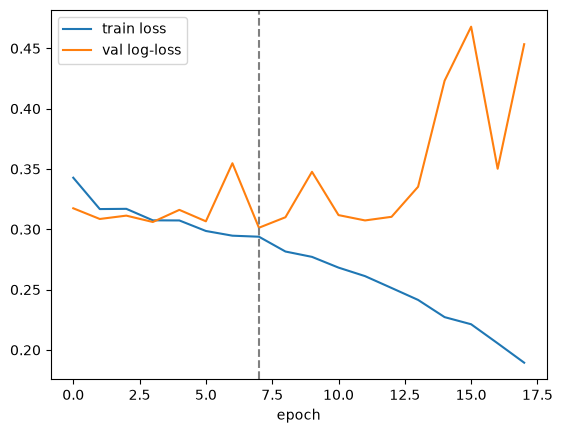

In [26]:
h = np.array(hist)
plt.plot(h[:, 0], label="train loss"); plt.plot(h[:, 1], label="val log-loss")
plt.axvline(best_ep - 1, ls="--", c="gray"); plt.legend(); plt.xlabel("epoch"); plt.show()

1. Train loss falls steadily (0.34 --> 0.19)
2. Val log-loss never really improves

In [27]:
class SpatialDS(torch.utils.data.Dataset):
    def __init__(self, ix, augment=False):
        self.X, self.y, self.augment = X_sp[ix], torch.from_numpy(y[ix]), augment
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i].astype(np.float32))      # (C, H, W)
        if self.augment and torch.rand(1).item() < 0.5:
            x = x.flip(1)                                        # mirror the y axis (left/right)
        return x, self.y[i]

def make_sp_loader(split, shuffle, augment=False):
    return DataLoader(SpatialDS(idx[split], augment), batch_size=128, shuffle=shuffle)

class CNN(nn.Module):
    def __init__(self, ch=(16, 32, 32), k=3, dropout=0.5, hidden=32):
        super().__init__()
        layers, c_in = [], 6
        for c in ch:
            layers += [nn.Conv2d(c_in, c, k, padding=k // 2), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d((3, 4)), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(ch[-1] * 12, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

torch.manual_seed(42)
sp_train = make_sp_loader("train", True, augment=True)          # augment train only
sp_val, sp_test = make_sp_loader("val", False), make_sp_loader("test", False)
cnn, hist, best_ep = train_model(CNN(), sp_train, sp_val, lr=3e-4, weight_decay=1e-4, patience=15)
print("best epoch:", best_ep, {k: round(v, 3) for k, v in evaluate(y[idx["val"]], predict(cnn, sp_val)).items()})

best epoch: 28 {'log_loss': 0.293, 'auc': 0.736, 'brier': 0.083}


In [28]:
def run_cnn(ch=(16, 32, 32), k=3, lr=3e-4, dropout=0.5, seeds=(0, 1)):
    ll, auc, ep = [], [], []
    for s in seeds:
        torch.manual_seed(s)
        m, _, e = train_model(CNN(ch, k, dropout), sp_train, sp_val, lr=lr, weight_decay=1e-4, patience=15)
        met = evaluate(y[idx["val"]], predict(m, sp_val))
        ll.append(met["log_loss"]); auc.append(met["auc"]); ep.append(e)
    return dict(ll=np.mean(ll), ll_sd=np.std(ll), auc=np.mean(auc), epoch=np.mean(ep))

base = dict(ch=(16, 32, 32), k=3, lr=3e-4)
trials = [base,
          {**base, "ch": (16, 32)},        # fewer conv layers
          {**base, "ch": (32, 64, 64)},    # wider
          {**base, "k": 5},                # bigger kernel
          {**base, "lr": 1e-3}]            # higher lr

rows = []
for cfg in trials:
    r = run_cnn(**cfg)
    rows.append({**cfg, **r})
    print(rows[-1])                        # prints as each finishes
pd.DataFrame(rows).sort_values("ll").round(4)

{'ch': (16, 32, 32), 'k': 3, 'lr': 0.0003, 'll': np.float64(0.29016925394535065), 'll_sd': np.float64(0.00216694176197052), 'auc': np.float64(0.7426072123235663), 'epoch': np.float64(31.0)}


KeyboardInterrupt: 

In [30]:
print(len(rows))

1


In [31]:
pd.DataFrame(rows).round(4)

,ch,k,lr,ll,ll_sd,auc,epoch
0,"(16, 32, 32)",3,0.0003,0.2902,0.0022,0.7426,31.0


In [32]:
# edit train_model call inside run_cnn: patience=8 and max_epochs=60, then
for cfg in [t for t in trials if t not in [{k: r[k] for k in ("ch", "k", "lr")} for r in rows]]:
    r = run_cnn(**cfg); rows.append({**cfg, **r}); print(rows[-1])

{'ch': (16, 32), 'k': 3, 'lr': 0.0003, 'll': np.float64(0.28417421877384186), 'll_sd': np.float64(0.0005926936864852905), 'auc': np.float64(0.7566230848441353), 'epoch': np.float64(80.5)}


KeyboardInterrupt: 

In [33]:
def run_cnn(ch=(16, 32, 32), k=3, lr=3e-4, dropout=0.5, seeds=(0,), patience=8, max_epochs=50):
    ll, auc, ep = [], [], []
    for s in seeds:
        torch.manual_seed(s)
        m, _, e = train_model(CNN(ch, k, dropout), sp_train, sp_val, lr=lr, weight_decay=1e-4,
                              patience=patience, max_epochs=max_epochs)
        met = evaluate(y[idx["val"]], predict(m, sp_val))
        ll.append(met["log_loss"]); auc.append(met["auc"]); ep.append(e)
    return dict(ll=np.mean(ll), ll_sd=np.std(ll), auc=np.mean(auc), epoch=np.mean(ep))

screen = [{**base, "ch": (16, 32)},       # fewer conv layers
          {**base, "k": 5},               # bigger kernel
          {**base, "lr": 1e-3}]           # higher lr
for cfg in screen:
    r = run_cnn(**cfg); rows.append({**cfg, **r}); print(rows[-1])

{'ch': (16, 32), 'k': 3, 'lr': 0.0003, 'll': np.float64(0.28709760308265686), 'll_sd': np.float64(0.0), 'auc': np.float64(0.7493369114113646), 'epoch': np.float64(49.0)}
{'ch': (16, 32, 32), 'k': 5, 'lr': 0.0003, 'll': np.float64(0.29751768708229065), 'll_sd': np.float64(0.0), 'auc': np.float64(0.716016059745582), 'epoch': np.float64(18.0)}
{'ch': (16, 32, 32), 'k': 3, 'lr': 0.001, 'll': np.float64(0.2869139313697815), 'll_sd': np.float64(0.0), 'auc': np.float64(0.7516148157393827), 'epoch': np.float64(15.0)}


In [1]:
import os; os.makedirs("../results", exist_ok=True)

CNN_LR = 3e-4            # validated config. Use 1e-3 for the fast shortcut (and say so in your markdown)
cfg_cnn = dict(ch=(16, 32), k=3, dropout=0.5)

pv, pt = [], []
for seed in range(3):
    torch.manual_seed(seed)
    m, _, ep = train_model(CNN(**cfg_cnn), sp_train, sp_val, lr=CNN_LR, weight_decay=1e-4,
                           patience=15, max_epochs=120)
    pv.append(predict(m, sp_val)); pt.append(predict(m, sp_test))
    np.save("../results/cnn_val.npy", np.array(pv))      # saved after every seed
    np.save("../results/cnn_test.npy", np.array(pt))
    print("seed", seed, "best epoch", ep,
          {k: round(v, 4) for k, v in evaluate(y[idx["val"]], pv[-1]).items()})

NameError: name 'torch' is not defined

In [1]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

2.14.1+cu130 True NVIDIA GeForce RTX 4060 Laptop GPU
